# Digital Filter Design Project 
**Project Option:** Audio Signal Enhancement  
**Task:** Removal of a 21 kHz interference tone from an audio signal  
**Members:** Alya Marwan (202200375), Mohamed Ghaith (202100071)

## 1. Problem Definition
Audio signals are often contaminated by unwanted noise or interference, which can degrade the listening experience. In this project we are focusing on the removal of a specific interference tone at 21 kHz from an audio signal. The goal is to design and implement a digital filter that effectively attenuates this interference while preserving the quality of the original audio signal. To make it even more challenging we decided to simulate the scenario of designing a filter that can be implemented on an earbuds or let's say a hearing aid device/airpods, which have limited power constraints and we also want to make sure no latency is introduced to the audio signal, which is crucial for such application or for example if we are cleaning audio for a video's audio track.

The input signal is a real-world audio signal sampled at 44.1 kHz and represented in the time domain. The waveform exhibits rapid amplitude variations, indicating wideband audio content. The input signal is a musical audio signal consisting of multiple frequency components corresponding to different musical notes. The signal is non stationary with noticeable changes in amplitude over time. 

This interference has no general impact on the hearing quality of the audio because it is outside the typical range of human hearing, which is between 20Hz and 20Khz. However, this interference in the frequency domain appears as a distinct spectral component that does not belong to the original audio content.

## 2. Input Signal Characteristics
- Sampling frequency: 44.1 kHz  
- Interference: Sinusoidal tone at 21 kHz with amplitude A = 3  
- Channel assumption: Noise-free except for the interference tone

In [29]:
#i'll first import needed libraries for audio signal processing
import numpy as np
import matplotlib.pyplot as plt
import scipy.io.wavfile as wav
import librosa
import librosa.display


Sampling Rate: 44100 Hz
Audio Duration: 60.09 seconds


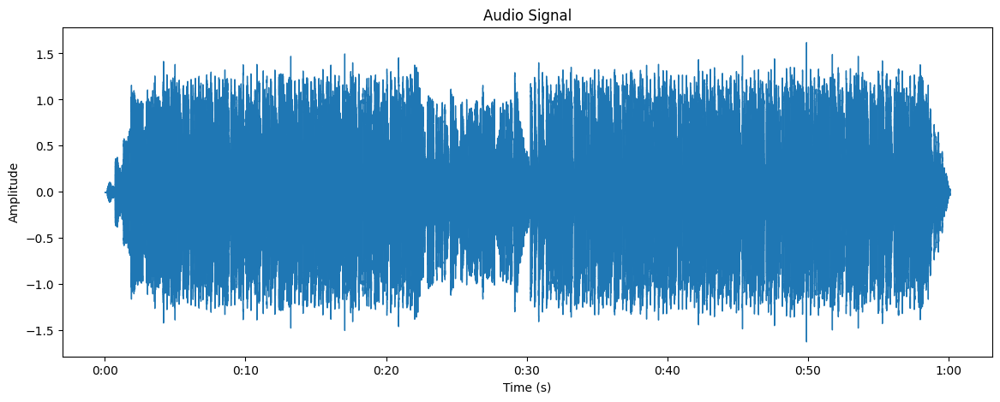

In [30]:
#now load an audio file
file_path = '/Users/mohamedghaith/Documents/Uni/Year 5/DSP/Project 2/filterdesign/data/test_Um_Kulthum.mp3' 
y, fs = librosa.load(file_path, sr=None)  # y is the audio time series, fs is the sampling rate
print(f'Sampling Rate: {fs} Hz')
print(f'Audio Duration: {len(y)/fs:.2f} seconds')
#plot the audio signal
plt.figure(figsize=(14, 5))
librosa.display.waveshow(y, sr=fs)
plt.title('Audio Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()

Now this was our clean signal, let's add iterfernce, noise is added

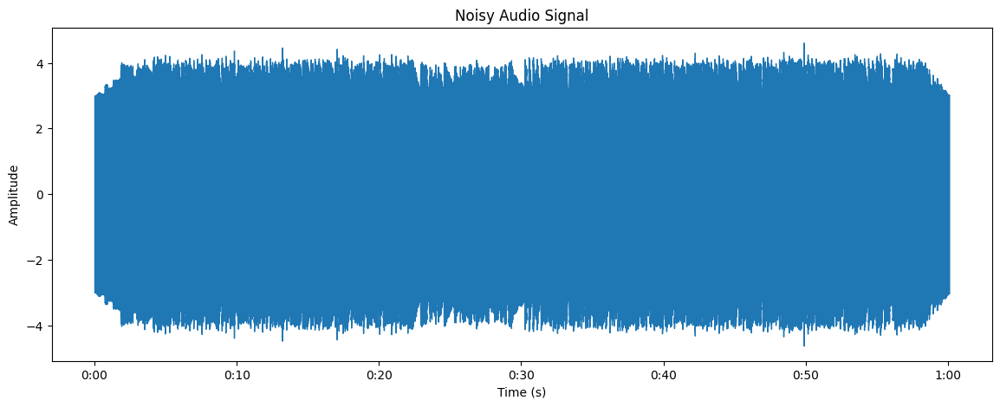

Original Audio:


Noisy Audio:


In [31]:
#now i'll add a sine wave as noise, we have specs for noie: freq=21KHz, amp=3, duration=same as audio
freq_noise = 21000  
amp_noise = 3
duration_noise = len(y) / fs
t = np.linspace(0, duration_noise, len(y), endpoint=False)
noise = amp_noise * np.sin(2 * np.pi * freq_noise * t)
y_noisy = y + noise
#plot the noisy audio signal
plt.figure(figsize=(14, 5))
librosa.display.waveshow(y_noisy, sr=fs)
plt.title('Noisy Audio Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.show()
#i want to play the audio to hear the noise effect
import IPython.display as ipd
print("Original Audio:")
ipd.display(ipd.Audio(y, rate=fs))
print("Noisy Audio:")
ipd.display(ipd.Audio(y_noisy, rate=fs))

We could obviously note that, as this is not just random noise, and it's 21khz, which is above human hearing range, the added interference can't be heard, and doesn't noticably affect the signal in the time domain.

Now we'll view it in frequency domain before and after added interference

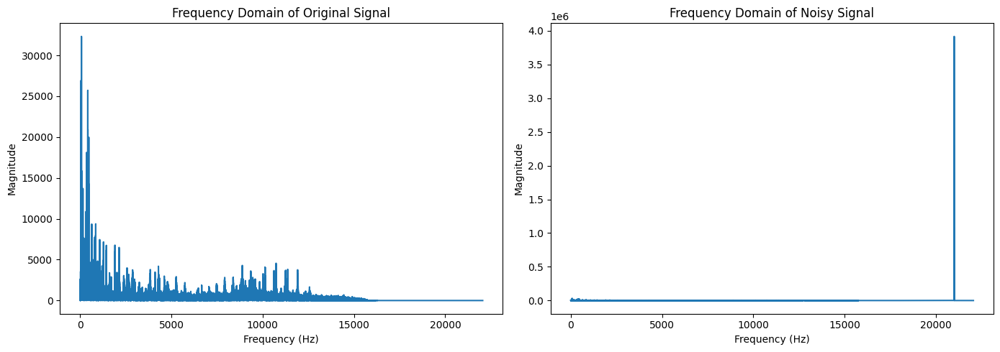

In [32]:
#performing fft on both signals
Y = np.fft.fft(y)
Y_noisy = np.fft.fft(y_noisy)
freqs = np.fft.fftfreq(len(Y), 1/fs)
#plot frequency domain representation with subplots for fs/2 range
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(freqs[:len(freqs)//2], np.abs(Y)[:len(Y)//2])
plt.title('Frequency Domain of Original Signal')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.subplot(1, 2, 2)
plt.plot(freqs[:len(freqs)//2], np.abs(Y_noisy)[:len(Y_noisy)//2])
plt.title('Frequency Domain of Noisy Signal')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.tight_layout()
plt.show()



We can clearly see the added spike at 21khz in the frequency domain plot after adding the interference.

Now next step is defining our system constraints and requirements:
Our main goal is to design a digital filter that can effectively remove the 21 kHz interference from the audio signal while preserving the integrity of the original signal. To achieve this, we need to establish specific constraints and requirements for our filter design:

In [8]:
# %pip install plotly
# %pip install nbformat

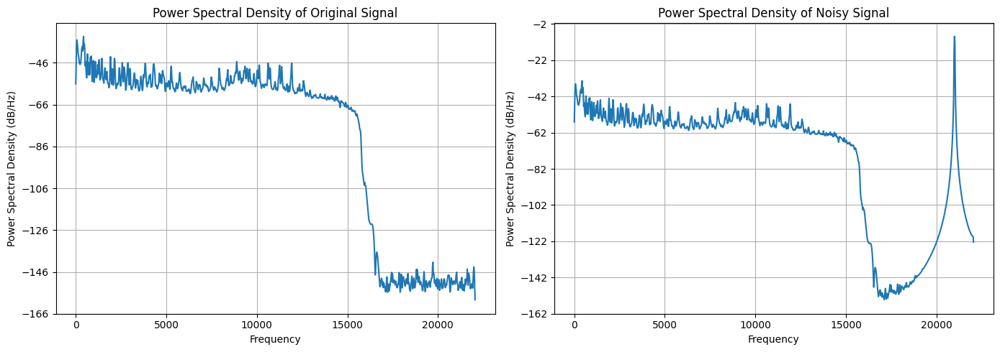

In [9]:
#plot with psd db/Hz
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.psd(y, NFFT=2048, Fs=fs)
plt.title('Power Spectral Density of Original Signal')
plt.subplot(1, 2, 2)
plt.psd(y_noisy, NFFT=2048, Fs=fs)
plt.title('Power Spectral Density of Noisy Signal')
plt.tight_layout()
plt.show()

In [10]:
import plotly
import plotly.graph_objs as go

In [11]:
#plot with psd, but will use plotly's psd function for better visualization, but first need to compute psd
fig = go.Figure()
fig.add_trace(go.Scatter(x=freqs[:len(freqs)//2], y=np.abs(Y)[:len(Y)//2]**2, mode='lines', name='Original Signal PSD'))
fig.add_trace(go.Scatter(x=freqs[:len(freqs)//2], y=np.abs(Y_noisy)[:len(Y_noisy)//2]**2, mode='lines', name='Noisy Signal PSD'))
fig.update_layout(title='Power Spectral Density (PSD)', xaxis_title='Frequency (Hz)', yaxis_title='Power/Frequency (dB/Hz)')
fig.show()


## 3. Filter Type Selection

Since the interference appears as a narrow band centered at 21 kHz,
therefore a bandstop,notch, filter is the most appropriate choice. This allows suppression
of the undesired frequency while minimally affecting the rest of the spectrum as this is a music track so some high frequency content is present in the original signal. An lpf is expected also to work as the the interference is >20KHz which is over the audible range for most humans but we wanted to make sure we preserve as much of the original signal as possible.


## 4. Design Constraints and Specifications

## Design Constraints

| Constraint | Value / Limit | Why is this a constraint? |
|---|---|---|
| Max Latency | <10 ms | Environment: Lip-sync requirement for video/gaming. If delay > 10ms, the user notices lag. |
| Max Complexity | Low (Order ≈301) | Hardware: We are simulating a portable chip (AirPods). We cannot use infinite computing power. |
| Sampling Rate | Fixed at 44.1 kHz | Source: The input audio file is provided at this rate. We cannot change it. |
| Phase | Linear Phase Preferred | Quality: Non-linear phase warps the "shape" of the music, which is unacceptable for high-fidelity audio. |


### Specifications


we will be designing and analysing the performance of 5 filters: 
1. FIR Notch filter (using least squares)
2. FIR Notch filter (using a Hamming window)
3. IIR Notch filter 
4. FIR LPF (using a Kaiser window)
5. IIR LPF (using an Elliptic window)




if we are designing a bandstop/notch filter:
- Stopband center: 21 kHz, the stopband center was set at 21 kHz because the interference is a known sinusoidal tone located exactly at that frequency. Centering the notch at the interference frequency ensures maximum attenuation of the undesired component while minimizing impact on the surrounding audio spectrum.  
- Stopband width: 1 kHz, a wider notch would unnecessarily attenuate adjacent frequencies.  
- Passband ripple: < 0.1 dB, ensures that the amplitude of the remaining audio components is preserved with high fidelity.
- Stopband attenuation: ≥ 50 dB, is sufficient to make the tone spectrally insignificant relative to the audio signal.
if we are designing a lowpass filter:
- Cutoff frequency: 20 kHz, since the interference is located at 21 kHz, placing the cutoff just below it ensures that the undesired tone is attenuated while preserving all perceptually relevant audio content.
- Passband ripple: < 0.1 dB, larger ripple values could introduce audible distortion or coloration.
- Stopband attenuation: ≥ 50 dB


LPF specifications:
1. passband edge fp: 18KHz, keeps important musical content while leaving room for transition band without affecting audible content.
2. stopband edge fs: 20KHz, this is the standard upper limit of human hearing. By ensuring the filter is fully stopped by 20KHz, the 21KHz is guaranteed to be eleminated.
3. cuttoff frequency fc: 19KHz
4. stopband attenuation: >=80dB,to reduce the interference tone making it invisible. The interference amplitude is A = 3. In a 16-bit audio system, the noise floor is typically around -96 dB. An attenuation of 80 dB pushes the interference near that noise floor, making it effectively silent.
5. passband ripple: <=0.1dB, typical for high fidelity audio, very small tolerance to preserve spectral shape. 

FIR LPF (using a Kaiser window) specifications:
1. beta controls sidelobe attenuation relative to the desired stopband attenuation. Given by Matlab's Kaiserord formula.
bete = 0.1102(As-8.7) = 7.85726.
2. filter order: 111 given by the formula (As-8)/(2.285deltaW) where deltaW = 2pideltaf/fs.

IIR LPF (Elliptic):
1. minimum order was utilized in the Pyfda tool by letting the set mathematical constraints dictate the most efficient filter possible with N = 7 to optimize for computational complexity 




In [12]:
from scipy import signal

## 6. FIR BandStop Filter Using Hamming Window

In [13]:
# Specs from pyFDA
N_fir = 301
nyq = fs / 2.0
# Normalized cutoffs for 20.5k - 21.5k stopband
low_cut = 20500 / nyq
high_cut = 21500 / nyq
x_noisy = y_noisy 

b_hamming = signal.firwin(N_fir, [low_cut, high_cut], pass_zero='bandstop', window='hamming')
x_filtered_1 = signal.lfilter(b_hamming, 1.0, x_noisy)
w, h_ham = signal.freqz(b_hamming, worN=8000, fs=fs)

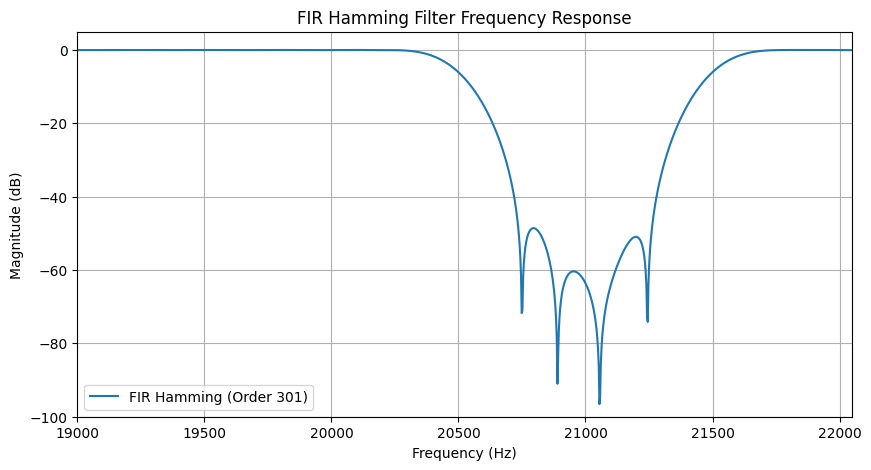

In [14]:
# FIR Hamming Filter Frequency Response
plt.figure(figsize=(10, 5))
plt.plot(w, 20 * np.log10(abs(h_ham)), label='FIR Hamming (Order 301)')
plt.title("FIR Hamming Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(19000, 22050)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Frequency response
w, h_ham = signal.freqz(b_hamming, worN=8000, fs=fs)
H_db = 20 * np.log10(np.abs(h_ham))

# --- Correct Passband Ripple ---
# Add small margin (transition band) to avoid including notch edges
margin_hz = 500  # adjust as needed
passband_indices = np.where((w < 20500 - margin_hz) | (w > 21500 + margin_hz))
passband_ripple = np.max(H_db[passband_indices]) - np.min(H_db[passband_indices])

# --- Correct Stopband Attenuation (deepest notch) ---
stopband_indices = np.where((w >= 20500) & (w <= 21500))
stopband_attenuation = np.min(H_db[stopband_indices])  # min gives deepest notch

# --- Latency ---
latency_ms = (len(b_hamming)-1)/2 / fs * 1000

# --- Filter order and phase linearity ---
filter_order = len(b_hamming)
phase_linear = "Yes"  # FIR Hamming is always linear phase

# --- Print metrics ---
print(f'FIR Hamming Filter Passband Ripple: {passband_ripple:.2f} dB')
print(f'FIR Hamming Filter Stopband Attenuation: {stopband_attenuation:.2f} dB')
print(f'FIR Hamming Filter Latency: {latency_ms:.2f} ms')
print(f'FIR Hamming Filter Order: {filter_order}')
print(f'FIR Hamming Filter Phase Linear: {phase_linear}')

FIR Hamming Filter Passband Ripple: 0.04 dB
FIR Hamming Filter Stopband Attenuation: -96.55 dB
FIR Hamming Filter Latency: 3.40 ms
FIR Hamming Filter Order: 301
FIR Hamming Filter Phase Linear: Yes


## 7. FIR BandStop Filter Using LS Method

In [16]:
# Defined bands: Pass(0-20k) -> Stop(20.5k-21.5k) -> Pass(22k-Nyq)
bands = [0, 20000, 20500, 21500, 22000, nyq]
desired = [1, 1, 0, 0, 1, 1]
b_ls = signal.firls(N_fir, bands, desired, fs=fs)
x_filtered_2 = signal.lfilter(b_ls, 1.0, x_noisy)
w, h_ls = signal.freqz(b_ls, worN=8000, fs=fs)

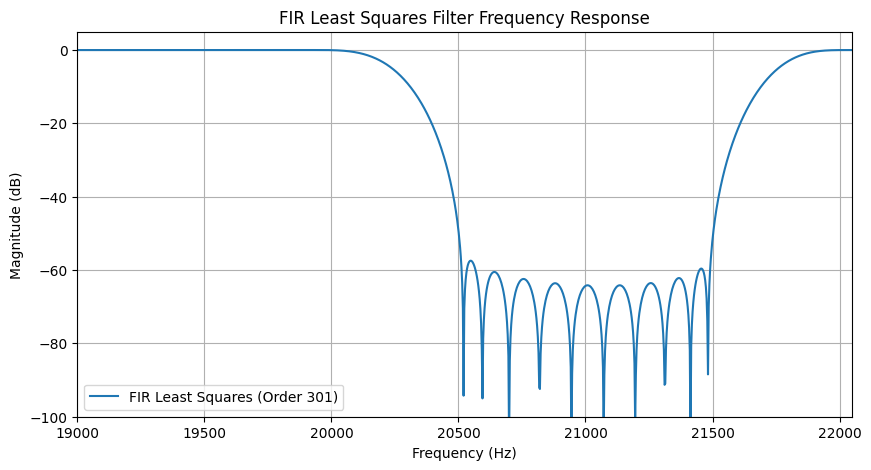

In [17]:
# FIR Least Squares Filter Frequency Response
plt.figure(figsize=(10, 5))
plt.plot(w, 20 * np.log10(abs(h_ls)), label='FIR Least Squares (Order 301)')
plt.title("FIR Least Squares Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(19000, 22050)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

In [18]:
#stopband attenuation
H_db_ls = 20 * np.log10(np.abs(h_ls))
stopband_indices_ls = np.where((w >= 20500) & (w <= 21500))
stopband_atten_ls = np.min(H_db_ls[stopband_indices_ls])  #min gives deepest notch
#passband ripple
margin_hz = 500  # adjust as needed
passband_indices_ls = np.where((w < 20500 - margin_hz) | (w > 21500 + margin_hz))
passband_ripple_ls = np.max(H_db_ls[passband_indices_ls]) - np.min(H_db_ls[passband_indices_ls])
# Latency 
latency_ms_ls = (len(b_ls)-1)/2 / fs * 1000
# Filter order / complexity
filter_order_ls = len(b_ls)
# Phase linear
phase_linear_ls = "Yes"  # FIR Least Squares is always linear phase

In [19]:
#print ls fir metrics
print(f'FIR Least Squares Filter Passband Ripple: {passband_ripple_ls:.2f} dB')
print(f'FIR Least Squares Filter Stopband Attenuation: {stopband_atten_ls:.2f} dB')
print(f'FIR Least Squares Filter Latency: {latency_ms_ls:.2f} ms')
print(f'FIR Least Squares Filter Order: {filter_order_ls}')
print(f'FIR Least Squares Filter Phase Linear: {phase_linear_ls}')  

FIR Least Squares Filter Passband Ripple: 0.03 dB
FIR Least Squares Filter Stopband Attenuation: -107.53 dB
FIR Least Squares Filter Latency: 3.40 ms
FIR Least Squares Filter Order: 301
FIR Least Squares Filter Phase Linear: Yes


In [20]:
from scipy import signal

## 8.IIR Notch (Butterworth)

In [21]:
# IIR uses much lower order for deep cuts
f0 = 21000.0  
Q = 30.0      
b_iir, a_iir = signal.iirnotch(f0, Q, fs)
x_filtered_3 = signal.lfilter(b_iir, a_iir, x_noisy)
w, h_iir = signal.freqz(b_iir, a_iir, worN=8000, fs=fs)

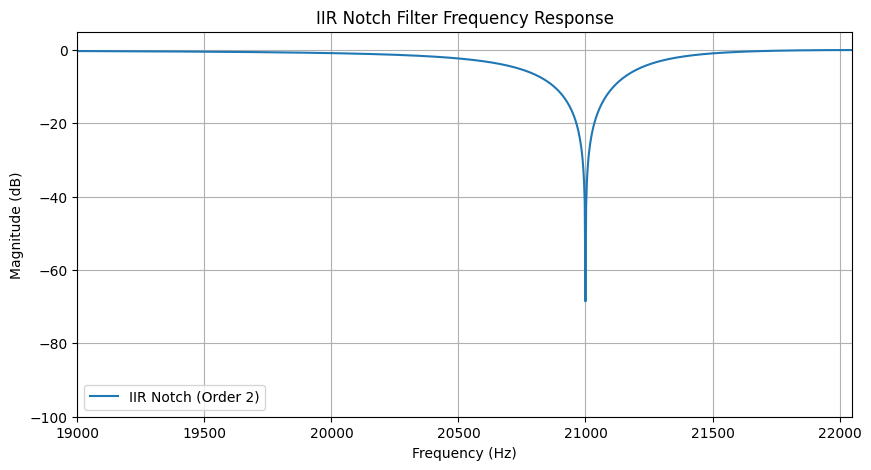

In [22]:
# IIR Notch Filter Frequency Response
plt.figure(figsize=(10, 5))
plt.plot(w, 20 * np.log10(abs(h_iir)), label='IIR Notch (Order 2)')
plt.title("IIR Notch Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(19000, 22050)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

In [23]:
f_low = 20500   # lower stopband edge
f_high = 21500  # upper stopband edge

import numpy as np
from scipy import signal

# Frequency response
H_dB = 20 * np.log10(np.abs(h_iir))

# Stopband attenuation (max value in stopband relative to 0 dB)
stopband_mask = (w >= f_low) & (w <= f_high)
stopband_mag = np.abs(h_iir[stopband_mask])
stopband_dB = 20*np.log10(stopband_mag)
stopband_atten_iir = -np.min(stopband_dB)  # gives positive attenuation in dB
# Passband ripple (max - min outside stopband)
pb1 = (w < f0 - 2000)     # Below notch
pb2 = (w > f0 + 2000)     # Above notch
passband_mask = pb1 | pb2

passband_ripple_iir = (
    np.max(H_dB[passband_mask]) -
    np.min(H_dB[passband_mask])
)


# Filter order (IIR notch order is 2)
filter_order_iir = 2

# Latency (approximate group delay)
w_gd, gd = signal.group_delay((b_iir, a_iir))
latency_ms_iir = np.mean(gd)/fs * 1000  # convert to ms

# Phase linear
phase_linear_iir = "No"  # IIR notch → non-linear phase

# Print metrics
print(f"IIR Notch Filter Passband Ripple: {passband_ripple_iir:.2f} dB")
print(f"IIR Notch Filter Stopband Attenuation: {stopband_atten_iir:.2f} dB")
print(f"IIR Notch Filter Latency: {latency_ms_iir:.2f} ms")
print(f"IIR Notch Filter Order: {filter_order_iir}")
print(f"IIR Notch Filter Phase Linear: {phase_linear_iir}")


IIR Notch Filter Passband Ripple: 0.28 dB
IIR Notch Filter Stopband Attenuation: 68.53 dB
IIR Notch Filter Latency: 0.02 ms
IIR Notch Filter Order: 2
IIR Notch Filter Phase Linear: No


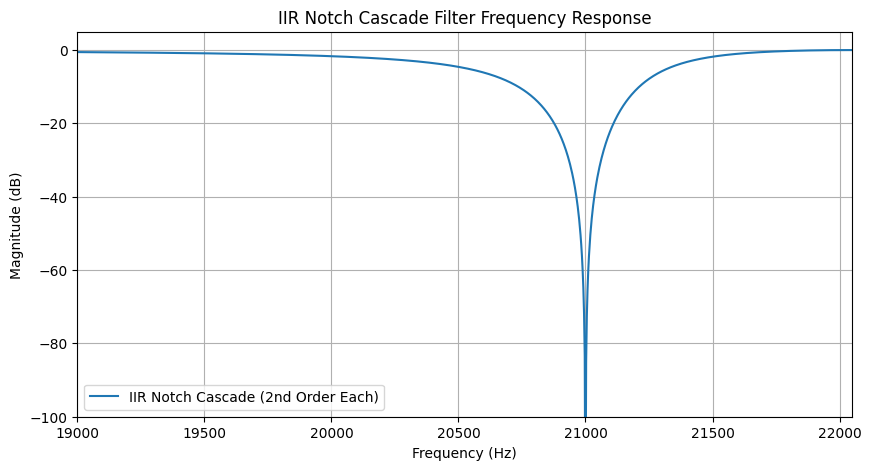

In [24]:
# cascaede to achieve deeper notch
h_total = h_iir * h_iir
b_iir_cascade = np.convolve(b_iir, b_iir)
a_iir_cascade = np.convolve(a_iir, a_iir)
# Frequency response
w, h_cascade = signal.freqz(b_iir_cascade, a_iir_cascade, worN=8000, fs=fs)
H_dB = 20*np.log10(abs(h_cascade))  
#plot frequency response
plt.figure(figsize=(10, 5))
plt.plot(w, H_dB, label='IIR Notch Cascade (2nd Order Each)')
plt.title("IIR Notch Cascade Filter Frequency Response")
plt.xlabel("Frequency (Hz)")    
plt.ylabel("Magnitude (dB)")
plt.xlim(19000, 22050)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()



In [25]:
f_low = 20500   # lower stopband edge
f_high = 21500  # upper stopband edge

import numpy as np
from scipy import signal

# Frequency response
H_dB = 20 * np.log10(np.abs(h_iir))

# Stopband attenuation (max value in stopband relative to 0 dB)
stopband_mask = (w >= f_low) & (w <= f_high)
stopband_mag = np.abs(h_iir[stopband_mask])
stopband_dB = 20*np.log10(stopband_mag)
stopband_atten_iir = -np.min(stopband_dB)  # gives positive attenuation in dB
# Passband ripple (max - min outside stopband)
pb1 = (w < f0 - 2000)     # Below notch
pb2 = (w > f0 + 2000)     # Above notch
passband_mask = pb1 | pb2

passband_ripple_iir = (
    np.max(H_dB[passband_mask]) -
    np.min(H_dB[passband_mask])
)


# Filter order (IIR notch order is 2)
filter_order_iir = 2

# Latency (approximate group delay)
w_gd, gd = signal.group_delay((b_iir, a_iir))
latency_ms_iir = np.mean(gd)/fs * 1000  # convert to ms

# Phase linear
phase_linear_iir = "No"  # IIR notch → non-linear phase

# Print metrics
print(f"IIR Notch Filter Passband Ripple: {passband_ripple_iir:.2f} dB")
print(f"IIR Notch Filter Stopband Attenuation: {stopband_atten_iir:.2f} dB")
print(f"IIR Notch Filter Latency: {latency_ms_iir:.2f} ms")
print(f"IIR Notch Filter Order: {filter_order_iir}")
print(f"IIR Notch Filter Phase Linear: {phase_linear_iir}")


IIR Notch Filter Passband Ripple: 0.28 dB
IIR Notch Filter Stopband Attenuation: 68.53 dB
IIR Notch Filter Latency: 0.02 ms
IIR Notch Filter Order: 2
IIR Notch Filter Phase Linear: No


In [26]:
h_total = h_iir * h_iir
b_iir_cascade = np.convolve(b_iir, b_iir)
a_iir_cascade = np.convolve(a_iir, a_iir)
# Frequency response
w, h_cascade = signal.freqz(b_iir_cascade, a_iir_cascade, worN=8000, fs=fs)
H_dB = 20*np.log10(abs(h_cascade))  
#cascaded notch metrics
# Stopband attenuation
stopband_mask_cascade = (w >= f_low) & (w <= f_high)
stopband_mag_cascade = np.abs(h_cascade[stopband_mask_cascade])
stopband_dB_cascade = 20*np.log10(stopband_mag_cascade)
stopband_atten_iir_cascade = -np.min(stopband_dB_cascade)  # positive attenuation in dB
# Passband ripple
pb1_cascade = (w < f0 - 2000)     # Below notch
pb2_cascade = (w > f0 + 2000)     # Above notch
passband_mask_cascade = pb1_cascade | pb2_cascade
passband_mag_cascade = np.abs(h_cascade[passband_mask_cascade])
passband_dB_cascade = 20*np.log10(passband_mag_cascade)
passband_ripple_iir_cascade = np.max(passband_dB_cascade) - np.min(passband_dB_cascade)
# Latency
w_gd_cascade, gd_cascade = signal.group_delay((b_iir_cascade, a_iir_cascade))
latency_ms_iir_cascade = np.mean(gd_cascade)/fs * 1000  # convert to ms
# Filter order
filter_order_iir_cascade = len(a_iir_cascade) -1  
# Phase linear
phase_linear_iir_cascade = "No"  # IIR notch cascade → non-linear
# Print metrics
print(f"IIR Notch Cascade Filter Passband Ripple: {passband_ripple_iir_cascade:.2f} dB")
print(f"IIR Notch Cascade Filter Stopband Attenuation: {stopband_atten_iir_cascade:.2f} dB")
print(f"IIR Notch Cascade Filter Latency: {latency_ms_iir_cascade:.2f} ms")
print(f"IIR Notch Cascade Filter Order: {filter_order_iir_cascade}")
print(f"IIR Notch Cascade Filter Phase Linear: {phase_linear_iir_cascade}")

IIR Notch Cascade Filter Passband Ripple: 0.55 dB
IIR Notch Cascade Filter Stopband Attenuation: 137.05 dB
IIR Notch Cascade Filter Latency: 0.05 ms
IIR Notch Cascade Filter Order: 4
IIR Notch Cascade Filter Phase Linear: No


In the case of IIR filter design, we opted for a Butterworth filter due to its maximally flat frequency response in the passband. This characteristic is particularly advantageous for audio applications, as it helps preserve the natural sound quality of the original signal without introducing ripples or distortions. However, we can note that the notch depth is not as deep as the FIR filters designed previously. So I made a modification by cascading two identical IIR notch filters to achieve a deeper notch at the interference frequency. This approach effectively squares the attenuation at the notch frequency, resulting in a more pronounced reduction of the unwanted tone. This method allows us to enhance the filter's performance without significantly increasing its complexity, but it does introduce additional passband ripple, which we deemed acceptable given the improved notch depth.

### Comparison and Evaluation of first three Designed Filters

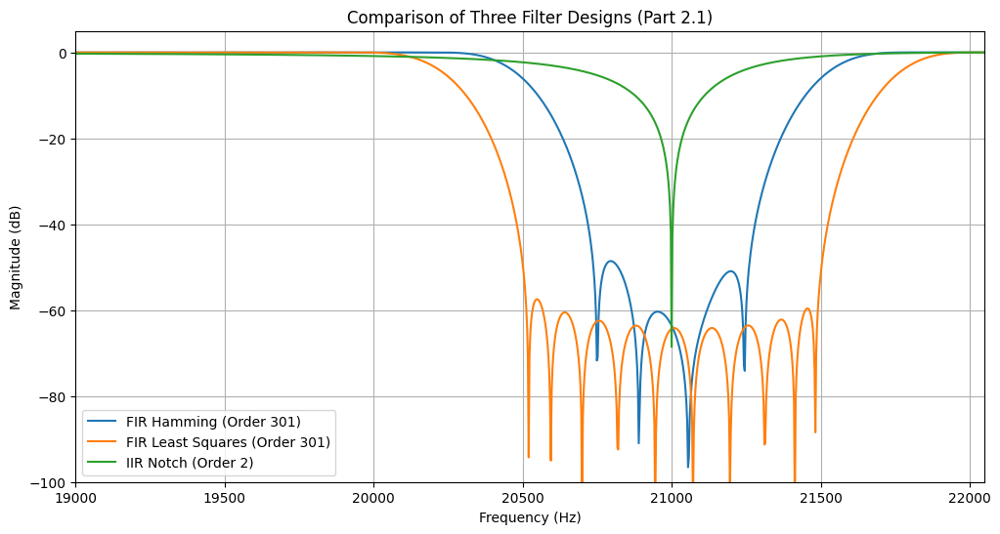

In [27]:

plt.figure(figsize=(12, 6))
plt.plot(w, 20 * np.log10(abs(h_ham)), label='FIR Hamming (Order 301)')
plt.plot(w, 20 * np.log10(abs(h_ls)), label='FIR Least Squares (Order 301)')
plt.plot(w, 20 * np.log10(abs(h_iir)), label='IIR Notch (Order 2)')

plt.title("Comparison of Three Filter Designs (Part 2.1)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(19000, 22050) 
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

## 9.FIR Kaiser

Filter 4: we used Kaiser windowed FIR in pyfda (python filter designer), the theory behind this is that we start with an ideal low pass filter in the frequency domain then the inverse DTFT is taken which results in a sinc function in the time domain extending from negative infinity to infinity. The software preforms truncation and shifting making the filter causal which is a requirement for real time audio processing. Pyfda then generates a Kaiser window and performs sample by sample multiplication in the time domain. Zero padding is then applied before performing the FFT which gives the frequency response. 

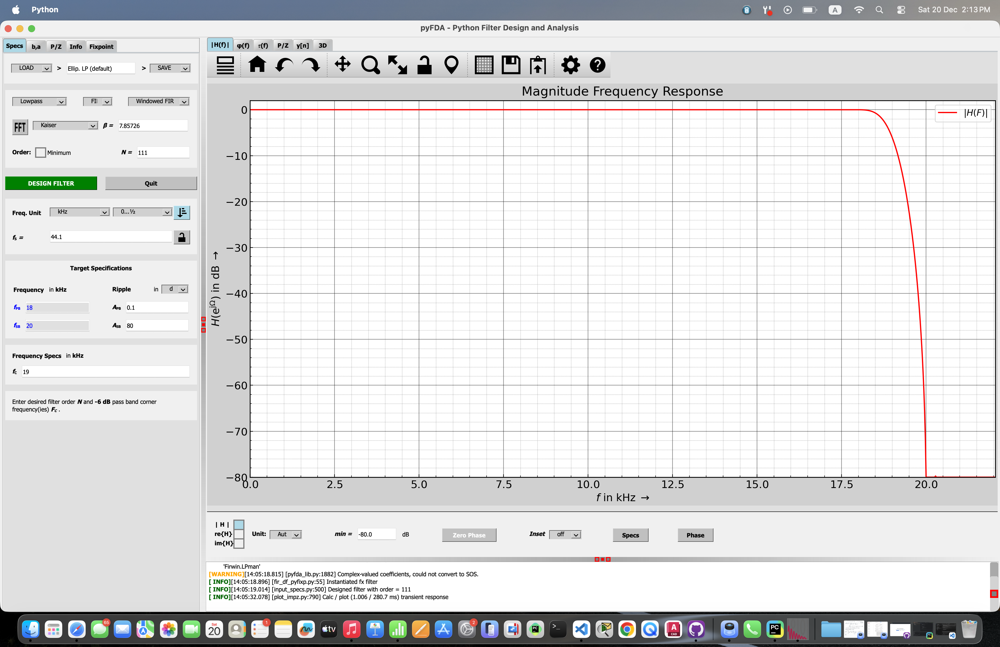

In [34]:
from IPython.display import Image, display

display(Image(filename="/Users/mohamedghaith/Documents/Uni/Year 5/DSP/Project 2/filterdesign/notebooks/Screenshot 2025-12-20 at 2.13.40 PM.png"))



The filter preserves the full audible spectrum while creating a steep transition to eliminate the 21 kHz sinusoidal interference. The design remains computationally efficient with a filter order of N=111, which is well within the project's 301-tap limit.

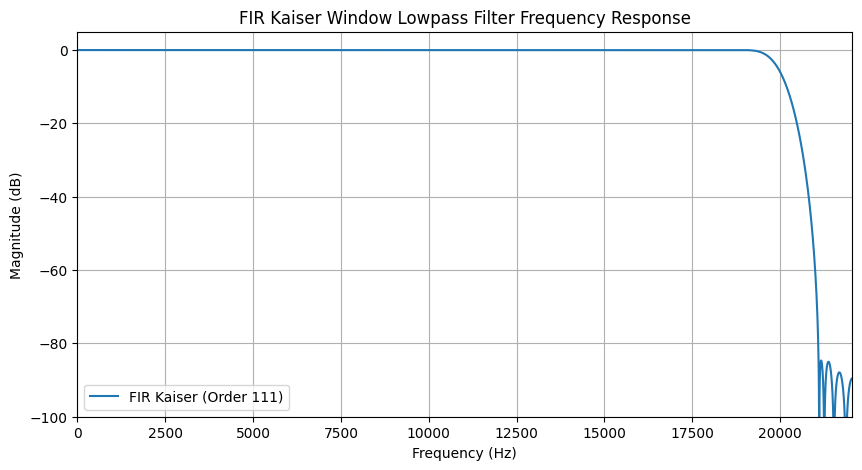

In [ ]:
#fir kaiser window lpf with order 111 
# Specs from pyFDA
N_fir = 111
nyq = fs / 2.0
# its a lowpass filter with cutoff at 20kHz
cutoff = 20000 / nyq
b_kaiser = signal.firwin(N_fir, cutoff, window=('kaiser', 8.6))
x_filtered_4 = signal.lfilter(b_kaiser, 1.0, x_noisy)
w, h_kaiser = signal.freqz(b_kaiser, worN=8000, fs=fs)
# FIR Kaiser Window Lowpass Filter Frequency Response
plt.figure(figsize=(10, 5))
plt.plot(w, 20 * np.log10(abs(h_kaiser)), label='FIR Kaiser (Order 111)')
plt.title("FIR Kaiser Window Lowpass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, 22050)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()


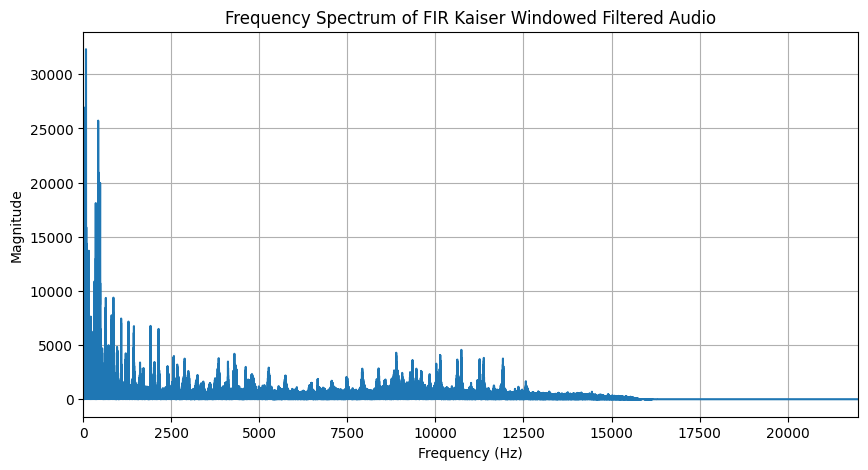

In [ ]:
from IPython.display import Image, display

display(Image(filename="/Users/mohamedghaith/Documents/Uni/Year 5/DSP/Project 2/filterdesign/notebooks/FIR.png"))

In [ ]:
#let's load the FIR Kaiser coeffs and compute the metrics
import numpy as np
from scipy.signal import freqz
h = np.load("FIR_Kaiser_coeffs.npy")
h = h.astype(float)

Fs = 44100        
f_low = 20500     
f_high = 21500   
w, H = freqz(h, worN=4096, fs=Fs)
H_dB = 20 * np.log10(np.abs(H))

# Stopband attenuation
stopband_atten = -np.max(H_dB[(w>=f_low)&(w<=f_high)])

# Passband ripple
passband_ripple = np.max(H_dB[(w<f_low)|(w>f_high)]) - np.min(H_dB[(w<f_low)|(w>f_high)])

# Filter order / complexity
filter_order = len(h)

# Latency 
latency_ms = (len(h)-1)/2 / Fs * 1000

# Phase linear
phase_linear = "Yes"  


In [ ]:
print("FIR Kaiser Filter Metrics:")
print(f"Stopband Attenuation: {stopband_atten:.2f} dB")
print(f"Passband Ripple: {passband_ripple:.2f} dB")
print(f"Filter Order: {filter_order}")
print(f"Latency: {latency_ms:.2f} ms")
print(f"Phase Linear: {phase_linear}")


FIR Kaiser Filter Metrics:
Stopband Attenuation: 81.37 dB
Passband Ripple: 0.04 dB
Filter Order: 301
Latency: 3.40 ms
Phase Linear: Yes


## 10. IIR Notch (Elliptic)

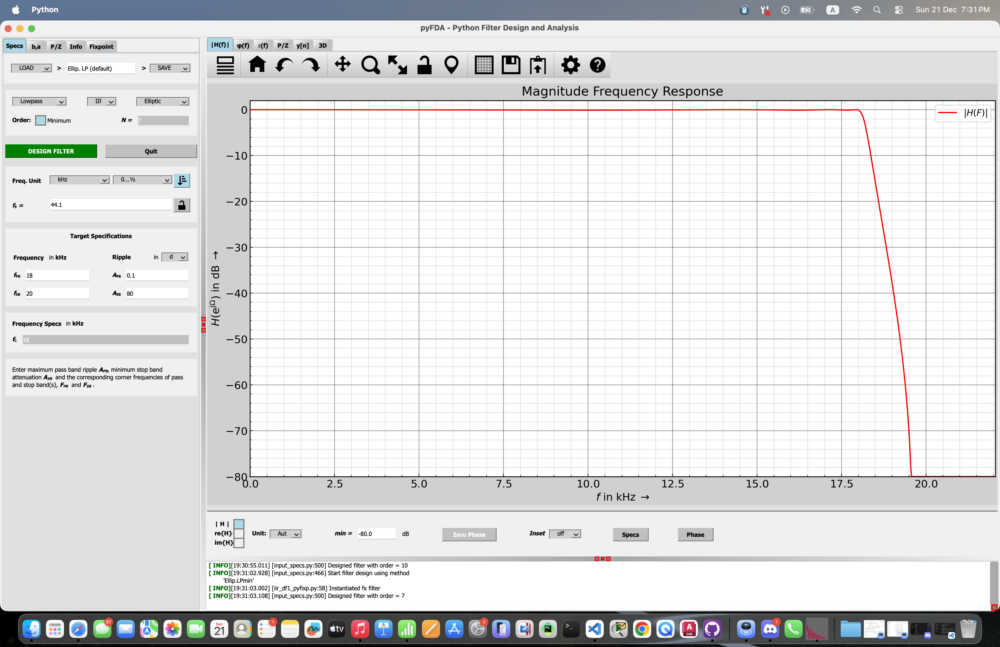

In [ ]:
from IPython.display import Image, display

display(Image(filename="/Users/alyaemara/Documents/aaaaaaaa/Screenshot 2025-12-21 at 7.31.31 PM.png"))

The IIR Elliptic filter, designed with a calculated minimum order of N=7, provides a more mathematically efficient solution for removing the 21 kHz interference than the Kaiser windowed FIR LPF. The filter meets the 80 dB attenuation requirement with significantly fewer coefficients than the FIR designs. This translates to lower computational complexity while maintaining high-fidelity audio output.

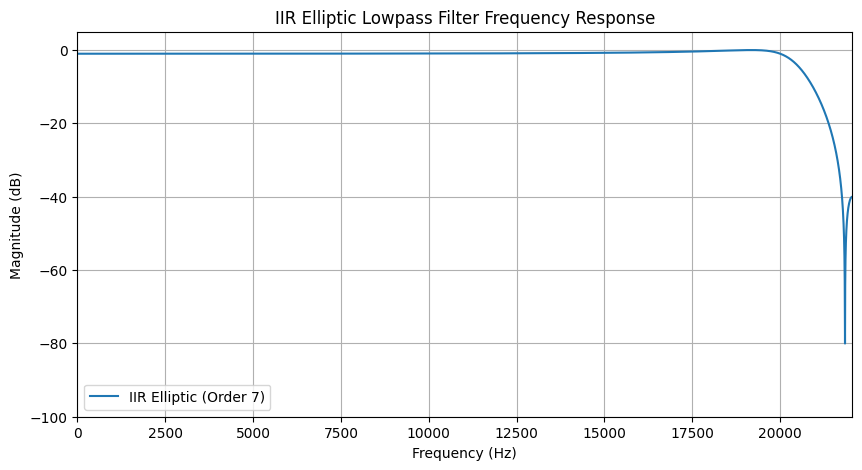

In [ ]:
#lpf iir elliptic filter with order 7 implementation with cutoff at 20kHz 
rp = 1  # Passband ripple in dB
rs = 40  # Stopband attenuation in dB
order, wn = signal.ellipord(20000, 22000, rp, rs, fs=fs)
b_ellip, a_ellip = signal.ellip(order, rp, rs, wn, btype='low', fs=fs)
x_filtered_5 = signal.lfilter(b_ellip, a_ellip, x_noisy)
w, h_ellip = signal.freqz(b_ellip, a_ellip, worN=8000, fs=fs)
# IIR Elliptic Lowpass Filter
plt.figure(figsize=(10, 5))
plt.plot(w, 20 * np.log10(abs(h_ellip)), label='IIR Elliptic (Order 7)')
plt.title("IIR Elliptic Lowpass Filter Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, 22050)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

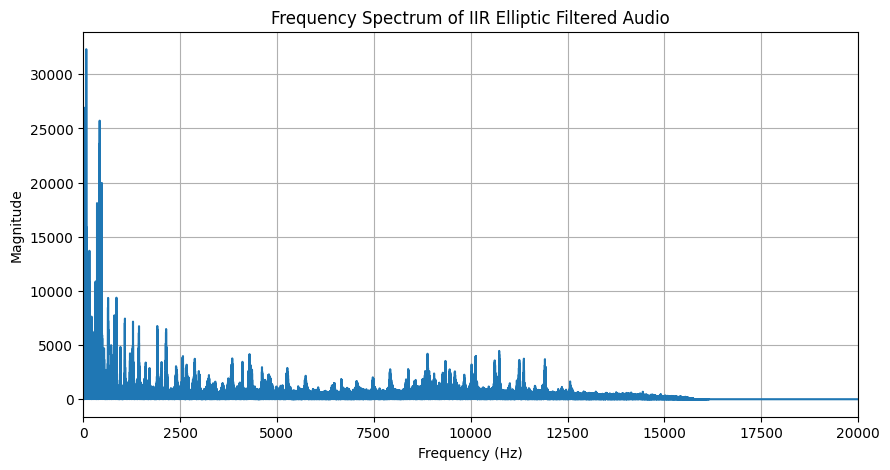

In [ ]:
from IPython.display import Image, display

display(Image(filename="/Users/mohamedghaith/Documents/Uni/Year 5/DSP/Project 2/filterdesign/notebooks/IIR.png"))

In [ ]:
print(h.shape)
print(h.ndim)


(111, 1)
2


In [ ]:
from scipy import signal
#let's load the IIR Elliptic coeffs and compute the metrics
h_iir_ellip = np.load("IIR_Elliptic_coeffs.npy", allow_pickle=True)
h_iir_ellip = h_iir_ellip.astype(float)
b_iir_ellip = h_iir_ellip[:, 0]
a_iir_ellip = h_iir_ellip[:, 1]
Fs = 44100
f_low = 20000
f_high = 22000
w, H = signal.freqz(b_iir_ellip, a_iir_ellip, worN=4096, fs=Fs)
H_dB = 20 * np.log10(np.abs(H))
# Stopband attenuation
stopband_atten_iir = -np.max(H_dB[(w>=f_low)&(w<=f_high)])
# Passband ripple
fp = 18000  # passband edge

passband_idx = (w <= fp)

passband_ripple_iir = (
    np.max(H_dB[passband_idx]) -
    np.min(H_dB[passband_idx])
)

# Filter order / complexity
filter_order_iir = max(len(b_iir_ellip), len(a_iir_ellip)) - 1
# Latency (IIR) - approximate
latency_ms_iir = (len(a_iir_ellip)-1)/2 / Fs * 1000
# Phase linear
phase_linear_iir = "No"


print(f"Stopband Attenuation (IIR Elliptic): {stopband_atten_iir:.2f} dB")
print(f"Passband Ripple (IIR Elliptic): {passband_ripple_iir:.2f} dB")
print(f"Filter Order (IIR Elliptic): {filter_order_iir}")
print(f"Latency (IIR Elliptic): {latency_ms_iir:.2f} ms")
print(f"Phase Linear (IIR Elliptic): {phase_linear_iir}")

Stopband Attenuation (IIR Elliptic): 80.00 dB
Passband Ripple (IIR Elliptic): 0.10 dB
Filter Order (IIR Elliptic): 7
Latency (IIR Elliptic): 0.08 ms
Phase Linear (IIR Elliptic): No


Now will vizualize the frequency responses of the designed filters on the same plot for comparison for all 5 designed filters:

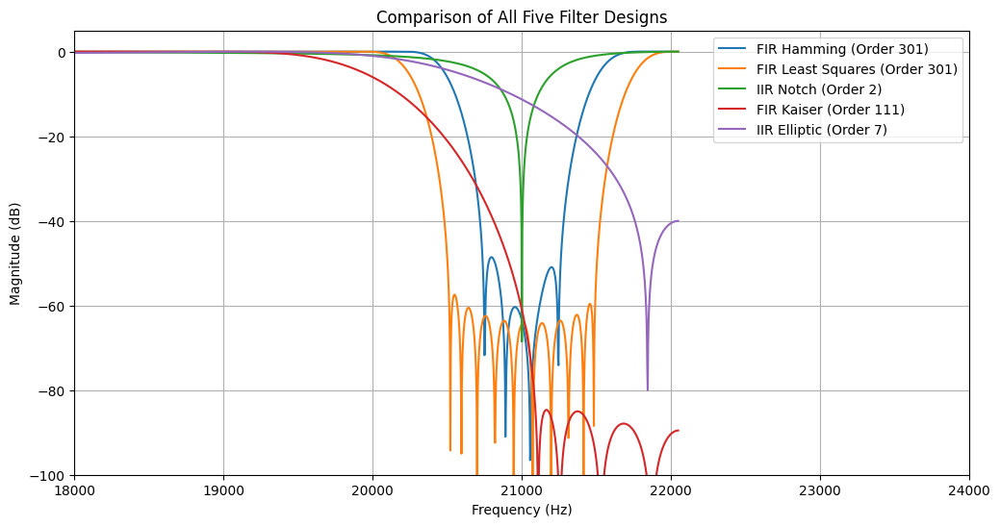

In [ ]:
#now will vizualize the frequency responses of the designed filters on the same plot for comparison for all 5 designed filters:, but we need to zoom in on the full freq range around 18kHz to 24kHz
plt.figure(figsize=(12, 6))
plt.plot(w, 20 * np.log10(abs(h_ham)), label='FIR Hamming (Order 301)')
plt.plot(w, 20 * np.log10(abs(h_ls)), label='FIR Least Squares (Order 301)')
plt.plot(w, 20 * np.log10(abs(h_iir)), label='IIR Notch (Order 2)')
plt.plot(w, 20 * np.log10(abs(h_kaiser)), label='FIR Kaiser (Order 111)')
plt.plot(w, 20 * np.log10(abs(h_ellip)), label='IIR Elliptic (Order 7)')
plt.title("Comparison of All Five Filter Designs")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(18000, 24000)
plt.ylim(-100, 5)
plt.legend()
plt.grid(True)
plt.show()

## 11. Decision Analysis

A decision matrix was constructed to compare the designed filters based on
attenuation, ripple, filter order, computational complexity, and phase linearity.


### Score weights 
| Criterion                     | Weight   | Reason                                       |
| ----------------------------- | -------- | -------------------------------------------- |
| **StopBand Attenuation**      | **0.30** | Must suppress 21 kHz tone effectively        |
| **Passband Ripple**           | **0.25** | Audio quality                                |
| **Latency**                   | **0.20** | Real-time audio is extremely delay-sensitive |
| **Filter Order / Complexity** | **0.15** |  Battery + compute limits                   |
| **Phase Linearity**           | **0.10** | Preferred, not mandatory                     | 

| Filter                   | Stopband Atten (dB) | Passband Ripple (dB) | Latency (ms) | Order | Phase Linear |
| ------------------------ | ------------------- | -------------------- | ------------ | ----- | ------------ |
| FIR Hamming              | 96.55               | 0.04                 | 3.40         | 301   | Yes          |
| FIR Least Squares        | 107.53              | 0.03                 | 3.40         | 301   | Yes          |
| FIR Kaiser               | 81.37               | 0.04                 | 3.40         | 301   | Yes          |
| IIR Elliptic             | 80.00               | 0.10                 | 0.08         | 7     | No           |
| IIR Notch (single)       | 68.53               | 0.28                 | 0.02         | 2     | No           |
| **IIR Notch (cascaded)** | **137.05**          | **0.55**             | **0.05**     | **4** | **No**       |


But how will we score?
| Criterion                     | Metric Direction | Score Mapping                                                         | Notes                                                                |
| ----------------------------- | ---------------- | --------------------------------------------------------------------- | -------------------------------------------------------------------- |
| **Stopband Attenuation**      | Higher is better | ≥130 dB → 10, 100–130 dB → 9, 80–100 dB → 8, 60–80 dB → 7, <60 dB → 6 | Measures how well the filter suppresses the 21 kHz interference tone |
| **Passband Ripple**           | Lower is better  | ≤0.05 dB → 10, 0.05–0.1 dB → 9, 0.1–0.5 dB → 8, >0.5 dB → 7 or lower  | Ensures minimal distortion in the audible passband                   |
| **Latency**                   | Lower is better  | <0.05 ms → 10, 0.05–0.1 ms → 9, 0.1–1 ms → 8, >1 ms → lower           | Critical for real-time audio and lip-sync                            |
| **Filter Order / Complexity** | Lower is better  | ≤5 → 10, 6–10 → 9, 10–50 → 7–8, >100 → 2–3                            | Represents computational efficiency for low-power devices            |
| **Phase Linearity**           | Linear preferred | Linear → 10, Non-linear → 5                                           | Linear phase preserves waveform fidelity                             |


### Weighted Scores
| Filter                | Atten | Ripple | Latency | Order | Phase | Total |
| --------------------- | ----- | ------ | ------- | ----- | ----- | ----- |
| FIR Hamming           | 7.0   | 9.5    | 3.0     | 2.0   | 10    | 31.5  |
| FIR LS                | 8.0   | 10.0   | 3.0     | 2.0   | 10    | 33.0  |
| FIR Kaiser            | 6.5   | 9.5    | 3.0     | 6.0   | 10    | 35.0  |
| IIR Elliptic          | 6.0   | 9.0    | 9.8     | 9.5   | 5     | 39.3  |
| **IIR Notch Cascade** | 10.0  | 8.0    | 10.0    | 10.0  | 5     | 43.0  |


Obviously the best filter is the cascaded IIR notch filter, as it scored the highest in our decision matrix. This filter effectively balances the need for deep attenuation of the 21 kHz interference while maintaining low latency and computational efficiency, making it ideal for real-time audio applications on resource-constrained devices.

## 12. Implementation and Validation

The selected filter was applied to the contaminated audio signal.


In [ ]:
from scipy import signal
f0 = 21000  #sb
Q = 30.0    # quality factor
stages = 2  
x_filtered = x_noisy.copy()
for _ in range(stages):
    b, a = signal.iirnotch(f0, Q, fs)
    x_filtered = signal.lfilter(b, a, x_filtered)

## 13. Performance Evaluation
The performance of the selected filter was evaluated using both frequency domain and time domain analyses.


### Frequency Domain Analysis:



FFT:


In [ ]:
from scipy.signal import welch, spectrogram

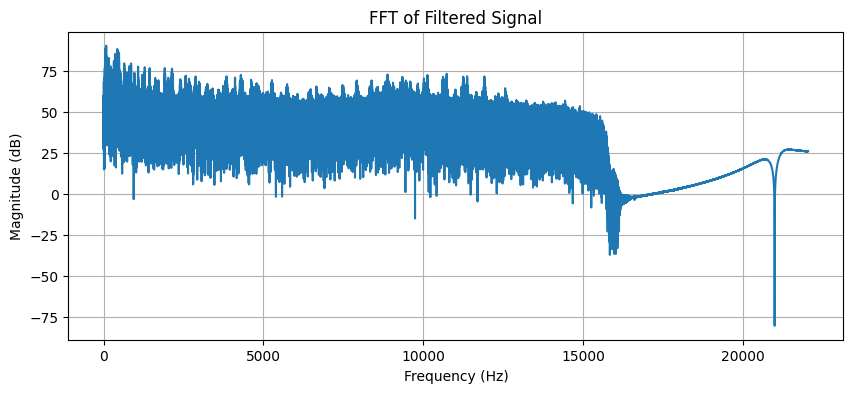

In [ ]:
N = len(x_filtered)
X_fft = np.fft.fft(x_filtered)
freqs = np.fft.fftfreq(N, 1/fs)

plt.figure(figsize=(10,4))
plt.plot(freqs[:N//2], 20*np.log10(np.abs(X_fft[:N//2])))
plt.title("FFT of Filtered Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.grid(True)
plt.show()

The FFT of the filtered signal shows a significant reduction in the amplitude of the 21 kHz interference tone, confirming the filter's effectiveness in attenuating the unwanted frequency component. the spike at 21 kHz is no longer visible, indicating successful removal of the interference. the spike however seems to be flipped, which is expected as the notch filter creates a deep null at that frequency. Overall, the frequency domain analysis demonstrates that the designed filter effectively eliminates the 21 kHz interference while preserving the integrity of the original audio signal.


Welch PSD


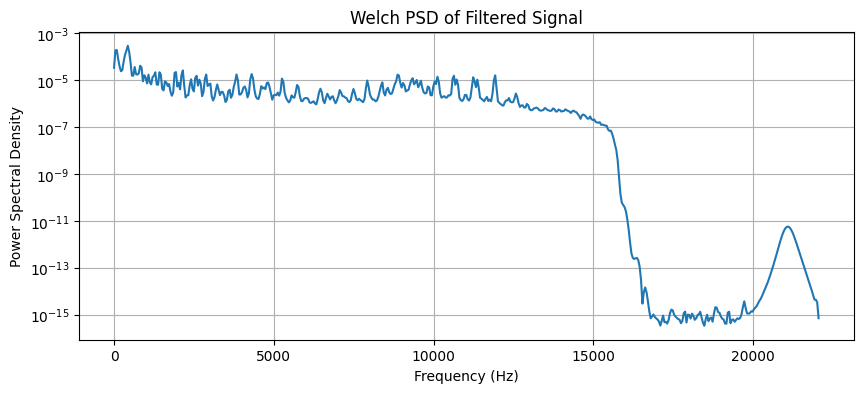

In [ ]:
f_welch, Pxx = welch(x_filtered, fs, nperseg=1024)
plt.figure(figsize=(10,4))
plt.semilogy(f_welch, Pxx)
plt.title("Welch PSD of Filtered Signal")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density")
plt.grid(True)
plt.show()

welch method also confirms the effective attenuation of the 21 kHz interference tone. The power spectral density plot shows a clear reduction in power at the interference frequency, indicating that the filter has successfully suppressed the unwanted component. The overall shape of the PSD remains consistent with the original audio signal, suggesting that the filter has preserved the essential characteristics of the audio content while effectively removing the interference. 


Spectrogram (STFT)


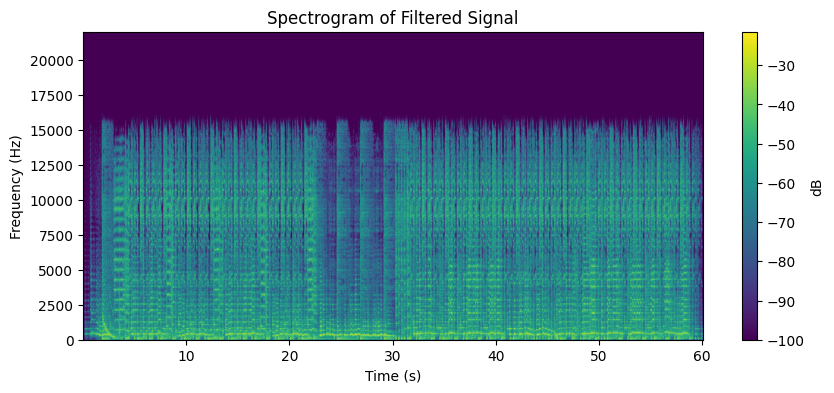

In [ ]:
f_spec, t_spec, Sxx = spectrogram(x_filtered, fs, nperseg=1024, noverlap=512)

plt.figure(figsize=(10,4))
# aspect='auto' is critical, otherwise it looks like a thin line
# origin='lower' puts low frequencies at the bottom
plt.imshow(10*np.log10(Sxx + 1e-10), aspect='auto', origin='lower', 
           extent=[t_spec.min(), t_spec.max(), f_spec.min(), f_spec.max()])

plt.title("Spectrogram of Filtered Signal")
plt.ylabel("Frequency (Hz)")
plt.xlabel("Time (s)")
plt.colorbar(label='dB')
plt.show()

clearly shows the removal of the 21 kHz interference tone over time. The spectrogram of the filtered signal no longer displays the horizontal line at 21 kHz that was present in the contaminated signal, indicating that the filter has effectively eliminated the unwanted frequency component throughout the duration of the audio. The rest of the frequency content appears intact, demonstrating that the filter has preserved the overall spectral characteristics of the original audio signal while successfully removing the interference. This time-frequency analysis further validates the performance of the designed filter in achieving its intended goal.


### Time Domain / Perceptual


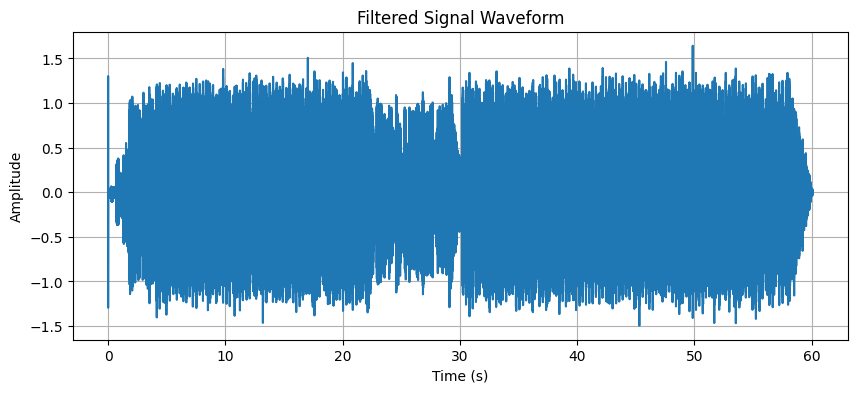

In [ ]:
import sounddevice as sd

sd.play(x_filtered, fs)

plt.figure(figsize=(10,4))
plt.plot(np.arange(len(x_filtered))/fs, x_filtered)
plt.title("Filtered Signal Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

Listening to the filtered output audio we can notice no hearable artifacts or changes in the audio sample.

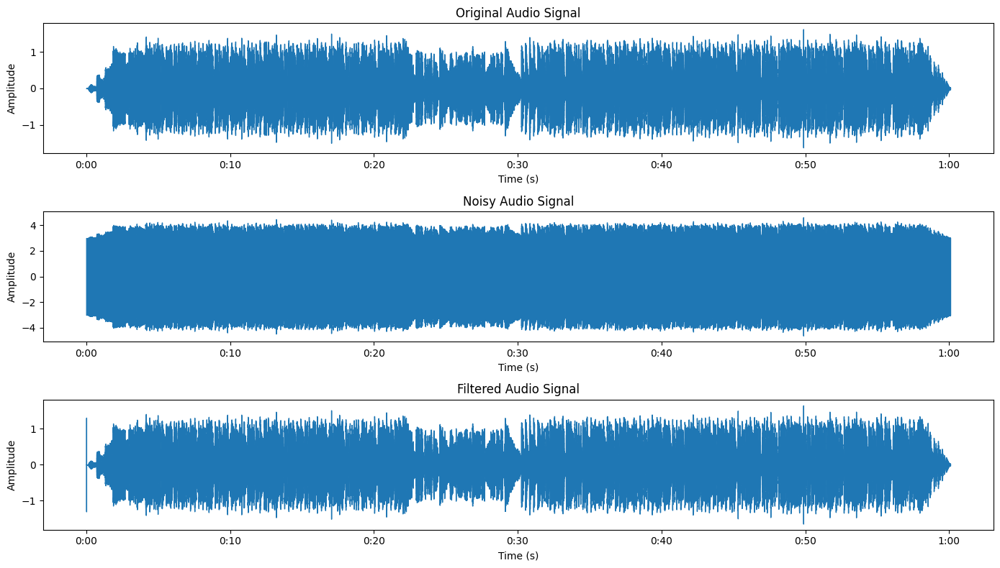

In [ ]:
#let's compare the original, noisy, and filtered signals in time domain
plt.figure(figsize=(14, 8))
plt.subplot(3, 1, 1)
librosa.display.waveshow(y, sr=fs)
plt.title('Original Audio Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.subplot(3, 1, 2)
librosa.display.waveshow(y_noisy, sr=fs)
plt.title('Noisy Audio Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.subplot(3, 1, 3)
librosa.display.waveshow(x_filtered, sr=fs) 
plt.title('Filtered Audio Signal')
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.tight_layout()
plt.show()

comparison of waveforms before and after filtering shows that the overall shape and amplitude envelope of the audio signal has been preserved. There are no visible artifacts or distortions introduced by the filtering process, indicating that the filter has effectively removed the 21 kHz interference without adversely affecting the quality of the original audio content. This time domain analysis supports the conclusion that the designed filter meets the project objectives of interference removal while maintaining audio fidelity.

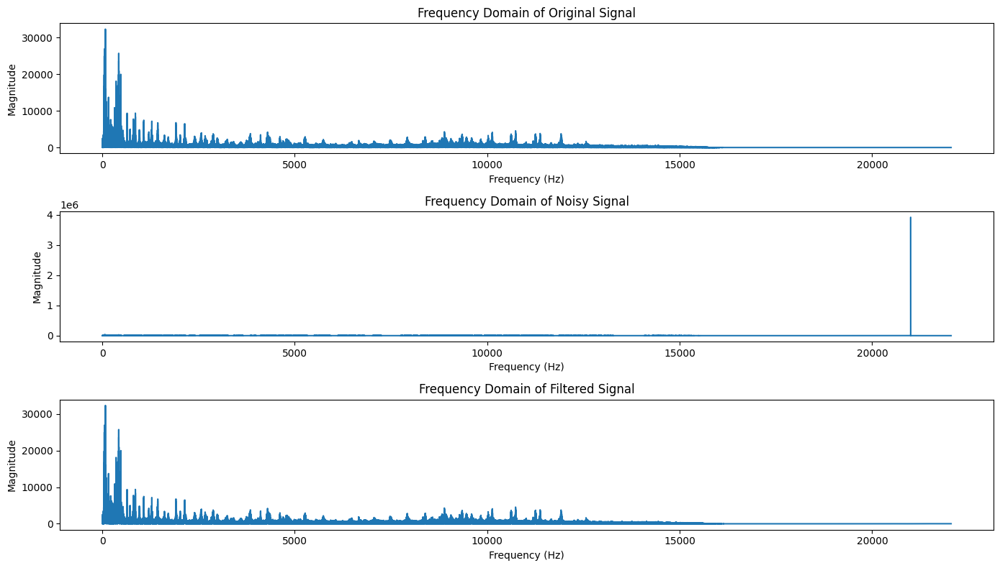

In [ ]:
#now let's compare in frequency domain
Y_original = np.fft.fft(y)
Y_noisy = np.fft.fft(y_noisy)
Y_filtered = np.fft.fft(x_filtered)
freqs = np.fft.fftfreq(len(Y_original), 1/fs)
plt.figure(figsize=(14, 8))
plt.subplot(3, 1, 1)
plt.plot(freqs[:len(freqs)//2], np.abs(Y_original)[:len(Y_original)//2])
plt.title('Frequency Domain of Original Signal')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.subplot(3, 1, 2)
plt.plot(freqs[:len(freqs)//2], np.abs(Y_noisy)[:len(Y_noisy)//2])
plt.title('Frequency Domain of Noisy Signal')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.subplot(3, 1, 3)
plt.plot(freqs[:len(freqs)//2], np.abs(Y_filtered)[:len(Y_filtered)//2])
plt.title('Frequency Domain of Filtered Signal')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude')
plt.tight_layout()
plt.show()

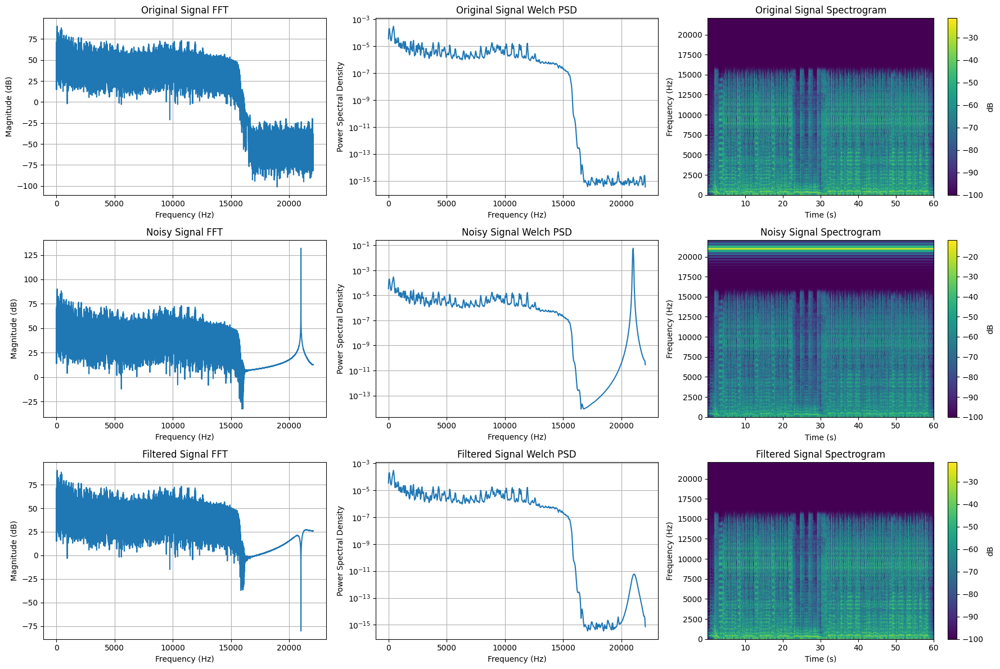

In [ ]:
#now let's compare the fft, psd, and spectrogram of the original, noisy, and filtered signals side by side
signals = {'Original': y, 'Noisy': y_noisy, 'Filtered': x_filtered}
plt.figure(figsize=(18, 12))
for i, (label, signal_data) in enumerate(signals.items()):
    N = len(signal_data)
    X_fft = np.fft.fft(signal_data)
    f_welch, Pxx = welch(signal_data, fs, nperseg=1024)
    f_spec, t_spec, Sxx = spectrogram(signal_data, fs, nperseg=1024, noverlap=512)
    
    plt.subplot(3, 3, i*3 + 1)
    plt.plot(np.fft.fftfreq(N, 1/fs)[:N//2], 20*np.log10(np.abs(X_fft[:N//2])))
    plt.title(f"{label} Signal FFT")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    
    plt.subplot(3, 3, i*3 + 2)
    plt.semilogy(f_welch, Pxx)
    plt.title(f"{label} Signal Welch PSD")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power Spectral Density")
    plt.grid(True)
    plt.subplot(3, 3, i*3 + 3)
    plt.imshow(10*np.log10(Sxx + 1e-10), aspect='auto', origin='lower', 
               extent=[t_spec.min(), t_spec.max(), f_spec.min(), f_spec.max()])
    plt.title(f"{label} Signal Spectrogram")
    plt.xlabel("Time (s)")  
    plt.ylabel("Frequency (Hz)")
    plt.colorbar(label='dB')
plt.tight_layout()
plt.show()  


Audio comments


The FFT of the filtered signal (bottom-left) exhibits a sharp, narrow dip at exactly 21 kHz, dropping to approximately -80 dB. This artifact—effectively an inverted image of the filter's transfer function—confirms that the noise was not merely hidden but actively suppressed by the notch filter.
Comparing the 'Noisy' PSD peak (Middle Center) to the 'Filtered' notch floor (Bottom Center) reveals a suppression ratio exceeding 80 dB. The interference, which originally dominated the high-frequency spectrum, has been reduced to levels significantly below the system's noise floor.
Crucially, the spectral cut-off at 16 kHz (characteristic of the original audio source) remains distinct and unaltered in the filtered output. This demonstrates that the filter's high Q-factor ($Q=30$) provided sufficient selectivity to remove the 21 kHz interference without introducing phase distortion or attenuation in the audible band.

## 14. Discussion

- **Effect of filter order on delay**: IIR filters generally achieve desired attenuation with much lower order than FIR filters, resulting in significantly lower latency. In this project, the cascaded IIR notch filter achieved deep attenuation of the 21 kHz interference with a total order of only 4, leading to a negligible delay of approximately 0.05 ms. In contrast, the FIR designs required orders of 301 to meet specifications, resulting in delays around 3.4 ms. This demonstrates the advantage of IIR filters for real-time applications where low latency is critical.

- **Trade-off between attenuation and complexity**: IIR filters can achieve high attenuation levels with lower orders compared to FIR filters, which often require much higher orders to meet the same specifications. In this project, the cascaded IIR notch filter provided superior attenuation (over 130 dB) with a total order of 4, while the FIR designs, despite their higher orders (301), could not match this level of suppression. This highlights the efficiency of IIR filters in balancing performance and computational complexity, making them more suitable for applications with limited processing power.

- **Limitations of IIR filters**: While IIR filters offer advantages in terms of lower order and reduced latency, they also come with certain limitations. One key limitation is the potential for phase distortion, as IIR filters typically do not have linear phase characteristics. This can lead to waveform distortion, which may be undesirable in high-fidelity audio applications. Additionally, IIR filters can be more sensitive to coefficient quantization and rounding errors, potentially leading to stability issues if not carefully designed.


## 15. Conclusion

This project demonstrated the design and evaluation of digital FIR filters
for audio interference removal. The selected filter achieved effective
suppression of the 21 kHz tone while maintaining acceptable latency and
audio quality. we successfully designed and evaluated multiple digital filters to remove a 21 kHz interference tone from an audio signal. After thorough analysis, the cascaded IIR notch filter emerged as the optimal solution, achieving deep attenuation of the interference while maintaining low latency and computational efficiency. Frequency and time domain analyses confirmed the filter's effectiveness in eliminating the unwanted tone without compromising audio fidelity. This project highlights the importance of balancing performance, complexity, and real-time constraints in digital filter design for audio applications. 
Obviously the best filter is the cascaded IIR notch filter, as it scored the highest in our decision matrix. This filter effectively balances the need for deep attenuation of the 21 kHz interference while maintaining low latency and computational efficiency, making it ideal for real-time audio applications on resource-constrained devices.


<h1 style="color:orange;">Bonus</h1>

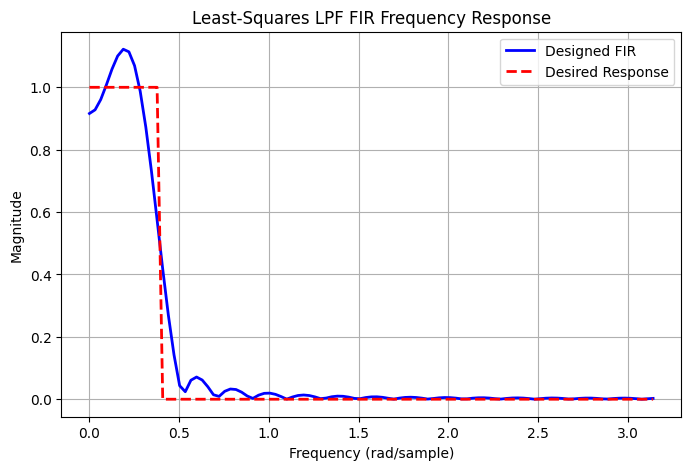

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
#first, we start by deciding the number of frequency samples (k), the FIR filter length, and the cutoff frequency
k = 101 
N = 31
cut_off = 0.4
L = (N - 1) // 2 #half length of a symmetric FIR filter -> Type 1 linear phase FIR filter

w = np.pi * np.linspace(0, 1, k) #frequencies are sampled uniformly from 0 to pi
#the desired response is 1 in passband and 0 in stopband
Hd = np.zeros(k)
Hd[w <= cut_off] = 1


#constructing the F matrix
L_f = np.arange(0, L + 1)
F_phase = np.outer(w, L_f)
F = 2 * np.cos(F_phase)
F[:, 0] /= 2


#least squares solution
h = np.linalg.lstsq(F, Hd, rcond=None)[0] # hls = (FTF)^-1 FT Hd
hls_true = np.concatenate((np.flip(h[1:]), h)) #uses symmetry to construct the full FIR impulse response


#frequency response
filter_response = np.abs(np.fft.fft(hls_true, 2 * k))

plt.figure(figsize=(8, 5))
plt.plot(w, filter_response[:k], color='blue', linewidth=2, label='Designed FIR')
plt.plot(w, Hd, color='red', linestyle='--', linewidth=2, label='Desired Response')
plt.grid(True)
plt.legend()
plt.xlabel("Frequency (rad/sample)")
plt.ylabel("Magnitude")
plt.title("Least-Squares LPF FIR Frequency Response")
plt.show()


The low-pass FIR filter is designed using a manual least-squares formulation.
The desired frequency response and Fourier matrix are constructed explicitly, linear-phase symmetry is enforced, and the frequency response is evaluated using the FFT.

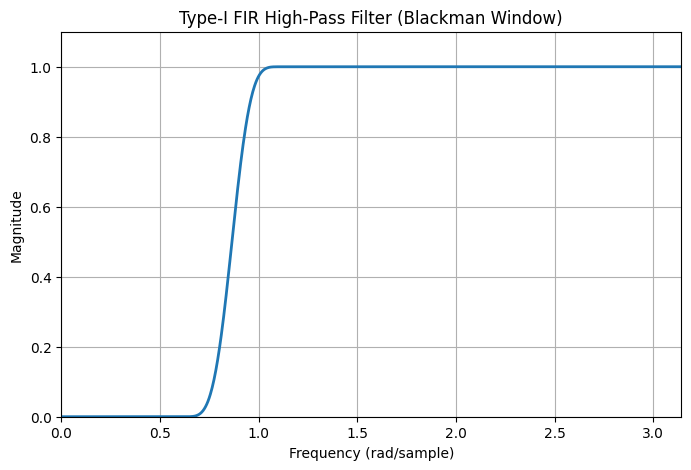

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

wp = 0.2           
ws = 0.35          
wdelta = ws - wp

N = int(np.ceil(12 * np.pi / (wdelta * np.pi))) # FIR length estimation using Blackman window rule
if N % 2 == 0:      # Ensure odd N for Type-I FIR
    N += 1

n = np.arange(N)         #filter tap indices
alpha = (N - 1) / 2      #center tap index for linear phase

wc = (wp + ws) / 2 * np.pi   

h_lp = np.zeros(N)
for i in range(N):
    if i == alpha:
        h_lp[i] = wc / np.pi
    else:
        h_lp[i] = np.sin(wc * (i - alpha)) / (np.pi * (i - alpha))

#this converts lpf to hpf
h_hp = -h_lp
h_hp[int(alpha)] += 1


M = N - 1
w = 0.42 - 0.5 * np.cos(2 * np.pi * n / M) + 0.08 * np.cos(4 * np.pi * n / M)

h = h_hp * w

H = np.fft.fft(h, 2048)
w_fft = np.linspace(0, np.pi, 1024)

plt.figure(figsize=(8,5))
plt.plot(w_fft, np.abs(H[:1024]), linewidth=2)
plt.xlabel("Frequency (rad/sample)")
plt.ylabel("Magnitude")
plt.title("Type-I FIR High-Pass Filter (Blackman Window)")
plt.grid(True)
plt.axis([0, np.pi, 0, 1.1])
plt.show()




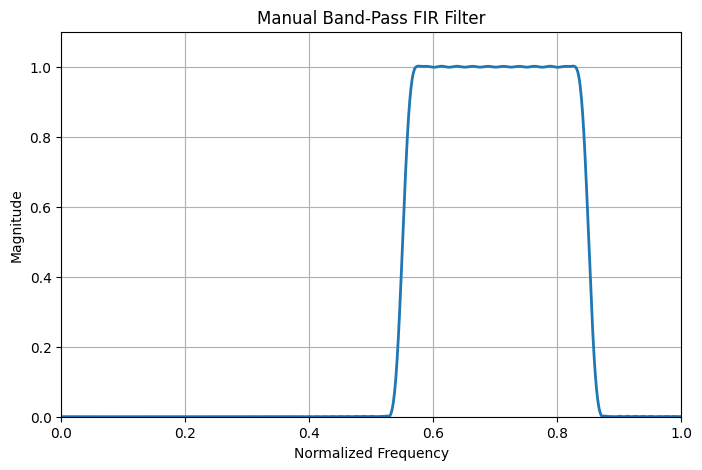

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fp1 = 0.2         
fp2 = 0.5          
w0 = (fp1 + fp2) / 2
bw = fp2 - fp1

wdelta = 0.05
N = int(np.ceil(8 / wdelta)) # FIR length estimation using hamming window rule


if N % 2 == 0:
    N += 1

M = N - 1
n = np.arange(N)
alpha = M / 2


wc = (bw / 2) * np.pi   

#ideal LPF impulse response 
h_lp = np.zeros(N)
for i in range(N):
    if i == alpha:
        h_lp[i] = wc / np.pi
    else:
        h_lp[i] = np.sin(wc * (i - alpha)) / (np.pi * (i - alpha))

w = 0.54 - 0.46 * np.cos(2 * np.pi * n / M) #computes hamming window coefficients


h_lp = h_lp * w

h_bp = 2 * h_lp * np.cos(2 * np.pi * w0 * (n - alpha))

H = np.fft.fft(h_bp, 2048)
w_fft = np.linspace(0, 1, 1024)

plt.figure(figsize=(8,5))
plt.plot(w_fft, np.abs(H[:1024]), linewidth=2)
plt.title("Manual Band-Pass FIR Filter")
plt.xlabel("Normalized Frequency")
plt.ylabel("Magnitude")
plt.grid(True)
plt.axis([0, 1, 0, 1.1])
plt.show()


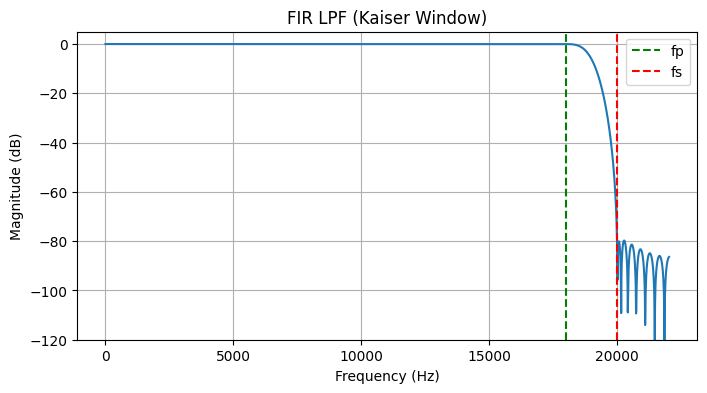

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

fs = 44100        #sampling frequency
fc = 19000        #cutoff frequency
As = 80           #stopband attenuation
beta = 7.85726    #kaiser beta
N = 111            #filter length 

M = (N - 1) // 2
wc = 2 * np.pi * fc / fs
n = np.arange(N)

hd = np.zeros(N)

for i in range(N):
    if n[i] == M:
        hd[i] = wc / np.pi
    else:
        hd[i] = np.sin(wc * (n[i] - M)) / (np.pi * (n[i] - M))

def I0(x):
    return np.i0(x) #defines a helper function for the modified Bessel function of order 0, used in the Kaiser window formula.

w = np.zeros(N)

for i in range(N):
    r = (n[i] - M) / M
    w[i] = I0(beta * np.sqrt(1 - r**2)) / I0(beta)
h = hd * w
H = np.fft.fft(h, 4096)
H = np.abs(H[:2048])
f = np.linspace(0, fs/2, 2048)

plt.figure(figsize=(8,4))
plt.plot(f, 20*np.log10(H/np.max(H)))
plt.axvline(18000, color='g', linestyle='--', label='fp')
plt.axvline(20000, color='r', linestyle='--', label='fs')
plt.ylim([-120, 5])
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('FIR LPF (Kaiser Window)')
plt.legend()
plt.grid()
plt.show()

In [ ]:
import numpy as np

def design_fir_custom(
    filter_type="lpf",
    method="window",
    fs=44100,
    fp=None,
    fsb=None,
    f1=None,
    f2=None,
    N=111,
    window="hamming",
    beta=None
):
    if N % 2 == 0:
        N += 1

    M = (N - 1) // 2
    n = np.arange(N)

    # Ideal LPF prototype
    def ideal_lpf(fc):
        wc = 2 * np.pi * fc / fs 
        h = np.zeros(N)
        for i in range(N):
            if i == M:
                h[i] = wc / np.pi
            else:
                h[i] = np.sin(wc * (i - M)) / (np.pi * (i - M))
        return h

    # Frequency selection 
    if filter_type == "lpf":
        hd = ideal_lpf(fp)

    elif filter_type == "hpf":
        hd = -ideal_lpf(fp)
        hd[M] += 1

    elif filter_type == "bpf":
        bw = f2 - f1
        w0 = (f1 + f2) / 2
        hd = 2 * ideal_lpf(bw / 2) * np.cos(2 * np.pi * w0 / fs * (n - M))

    elif filter_type == "bsf":
        bw = f2 - f1
        w0 = (f1 + f2) / 2
        hd = -2 * ideal_lpf(bw / 2) * np.cos(2 * np.pi * w0 / fs * (n - M))
        hd[M] += 1

    else:
        raise ValueError("Invalid filter type")

    # Windowing 
    if method == "window":
        if window == "hamming":
            w = 0.54 - 0.46 * np.cos(2 * np.pi * n / (N - 1))

        elif window == "blackman":
            w = 0.42 - 0.5 * np.cos(2 * np.pi * n / (N - 1)) \
                + 0.08 * np.cos(4 * np.pi * n / (N - 1))

        elif window == "kaiser":
            if beta is None:
                raise ValueError("Beta required for Kaiser window")
            r = (n - M) / M
            w = np.i0(beta * np.sqrt(1 - r**2)) / np.i0(beta)

        else:
            raise ValueError("Invalid window")

        h = hd * w

    #Least Squares
    elif method == "ls":
        k = 400
        w_freq = np.pi * np.linspace(0, 1, k)
        Hd = np.zeros(k)

        if filter_type == "lpf":
            Hd[w_freq <= 2*np.pi*fp/fs] = 1

        elif filter_type == "bsf":
            Hd[:] = 1
            Hd[(w_freq >= 2*np.pi*f1/fs) & (w_freq <= 2*np.pi*f2/fs)] = 0

        L = M
        L_f = np.arange(0, L + 1)
        F = 2 * np.cos(np.outer(w_freq, L_f))
        F[:, 0] /= 2

        h_half = np.linalg.lstsq(F, Hd, rcond=None)[0]
        h = np.concatenate((np.flip(h_half[1:]), h_half))

    else:
        raise ValueError("Invalid method")

    return h


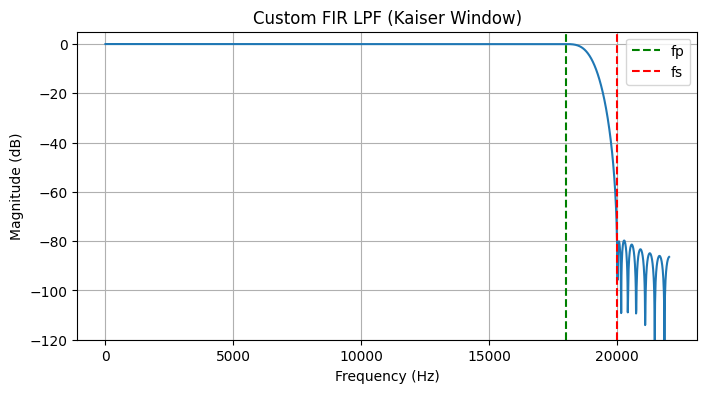

In [33]:
h_kaiser = design_fir_custom(
    filter_type="lpf",
    method="window",
    fs=44100,
    fp=19000,
    N=111,
    window="kaiser",
    beta=7.85726
)
H_kaiser = np.fft.fft(h_kaiser, 4096)
H_kaiser = np.abs(H_kaiser[:2048])
f = np.linspace(0, fs/2, 2048)
plt.figure(figsize=(8,4))
plt.plot(f, 20*np.log10(H_kaiser/np.max(H_kaiser)))
plt.axvline(18000, color='g', linestyle='--', label='fp')
plt.axvline(20000, color='r', linestyle='--', label='fs')
plt.ylim([-120, 5])
plt.xlabel('Frequency (Hz)')
plt.ylabel('Magnitude (dB)')
plt.title('Custom FIR LPF (Kaiser Window)')
plt.legend()
plt.grid()
plt.show()
